# LeetCode #1327: Sort Array by Parity

https://leetcode.com/problems/sort-array-by-parity/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(n)$ | $O(n)$ |
| **Optimal: Two Pointers ★** | $O(n)$ | $O(1)$ |

---

## Understanding the Methods

### Brute Force
Collect even-valued elements into one list and odd-valued elements into another, then concatenate. Linear time but requires $O(n)$ extra space for the two lists.

### Optimal: Two Pointers ★
Use a left pointer starting at 0 (looking for odd numbers to swap out) and a right pointer starting at n-1 (looking for even numbers to swap in). Advance each pointer past elements already on the correct side, and swap when left holds an odd and right holds an even. The array is rearranged in-place.

**Why this is better than Brute Force:** No auxiliary lists are allocated; all swaps happen in-place with $O(1)$ extra memory while maintaining the same $O(n)$ time complexity.

**Constraints:**
* 1 <= nums.length <= 5000
* 0 <= nums[i] <= 10000

## Solutions

### C#

In [ ]:
public class Solution {
    public int[] SortArrayByParity(int[] nums) {
        int left = 0, right = nums.Length - 1;
        while (left < right) {
            // Move left past elements already on the correct (even) side
            while (left < right && nums[left] % 2 == 0) left++;
            // Move right past elements already on the correct (odd) side
            while (left < right && nums[right] % 2 == 1) right--;
            if (left < right) {
                // left holds an odd, right holds an even — swap them into their correct halves
                (nums[left], nums[right]) = (nums[right], nums[left]);
                left++; right--;
            }
        }
        return nums;
    }
}

### Python

In [ ]:
class Solution:
    def sortArrayByParity(self, nums: list[int]) -> list[int]:
        left, right = 0, len(nums) - 1
        while left < right:
            # Move left past elements already on the correct (even) side
            while left < right and nums[left] % 2 == 0:
                left += 1
            # Move right past elements already on the correct (odd) side
            while left < right and nums[right] % 2 == 1:
                right -= 1
            if left < right:
                # left holds an odd, right holds an even — swap them into their correct halves
                nums[left], nums[right] = nums[right], nums[left]
                left += 1
                right -= 1
        return nums

### Go

In [ ]:
func sortArrayByParity(nums []int) []int {
    left, right := 0, len(nums)-1
    for left < right {
        // Move left past elements already on the correct (even) side
        for left < right && nums[left]%2 == 0 {
            left++
        }
        // Move right past elements already on the correct (odd) side
        for left < right && nums[right]%2 == 1 {
            right--
        }
        if left < right {
            // left holds an odd, right holds an even — swap them into their correct halves
            nums[left], nums[right] = nums[right], nums[left]
            left++
            right--
        }
    }
    return nums
}

### Rust

In [ ]:
impl Solution {
    pub fn sort_array_by_parity(mut nums: Vec<i32>) -> Vec<i32> {
        let (mut left, mut right) = (0, nums.len() - 1);
        while left < right {
            // Move left past elements already on the correct (even) side
            while left < right && nums[left] % 2 == 0 { left += 1; }
            // Move right past elements already on the correct (odd) side
            while left < right && nums[right] % 2 == 1 { right -= 1; }
            if left < right {
                // left holds an odd, right holds an even — swap them into their correct halves
                nums.swap(left, right);
                left += 1;
                right -= 1;
            }
        }
        nums
    }
}

## Example Scenarios

Two pointers close in from the ends. `left` skips over values that are already even, `right` skips over values that are already odd, and whenever both stop the pair is out of place — one swap fixes two elements at once and both pointers step inward. Nothing is allocated, so the partition is $O(n)$ time and $O(1)$ space.

### 1. Common Case — Four Elements, Two Swaps

**Input:** `nums = [3,1,2,4]`

`left = 0` stops on 3 (odd) and `right = 3` stops on 4 (even), so they swap: $[4,1,2,3]$, pointers move to 1 and 2. They stop again on 1 and 2 and swap: $[4,2,1,3]$. Now `left = 2 > right = 1` and the loop ends. **Output: `[4,2,1,3]`** — all evens before all odds. Any such arrangement is accepted; this algorithm produces one specific one.

### 2. Slightly Complex — Already Fully Partitioned

**Input:** `nums = [0,2,4,6,8]`

Every value is even, so the first inner loop walks `left` all the way up until `left == right` and stops there. `right` never moves, the `if left < right` guard fails, and the outer loop exits. **Zero swaps**, output unchanged. The `left < right` test inside *both* inner loops is what prevents the pointers from running past each other here.

### 3. Edge Case: Time Factor — Maximum Swaps

**Input:** `nums = [1,3,5,\ldots,4999,\ 0,2,4,\ldots,4998]` ($n = 5000$: all odds, then all evens)

Perfectly inverted. Every element is on the wrong side, so `left` and `right` stop immediately on each step and each iteration performs a swap: $n/2 = 2500$ swaps, the maximum any input can force. Both pointers still traverse the array only once between them, so the total is $O(n)$ regardless.

### 4. Edge Case: Space Factor — Strictly Alternating Values

**Input:** `nums = [1,2,3,\ldots,5000]` (alternating odd, even)

Counter-intuitively this needs only **1250** swaps, not 2500: half the odd values already sit in the right-hand half and half the even values already sit in the left-hand half, so both pointers skip a great deal. The point of this case is space — no auxiliary lists, no copy of the input, just `left`, `right` and a temporary during the swap. $O(1)$ extra memory for any $n$.

### 5. Almost-Impossible but Plausible — Single Element

**Input:** `nums = [10000]`

`left = right = 0`, so `left < right` is false before the body ever runs and the array is returned untouched. A one-element array is trivially partitioned either way. This is the input that catches an implementation using `left <= right` as the outer condition: the body would be entered, both inner loops would refuse to move (their own `left < right` guards fail), the `if left < right` swap would be skipped, and the outer condition would still hold — an infinite loop on a single-element array.


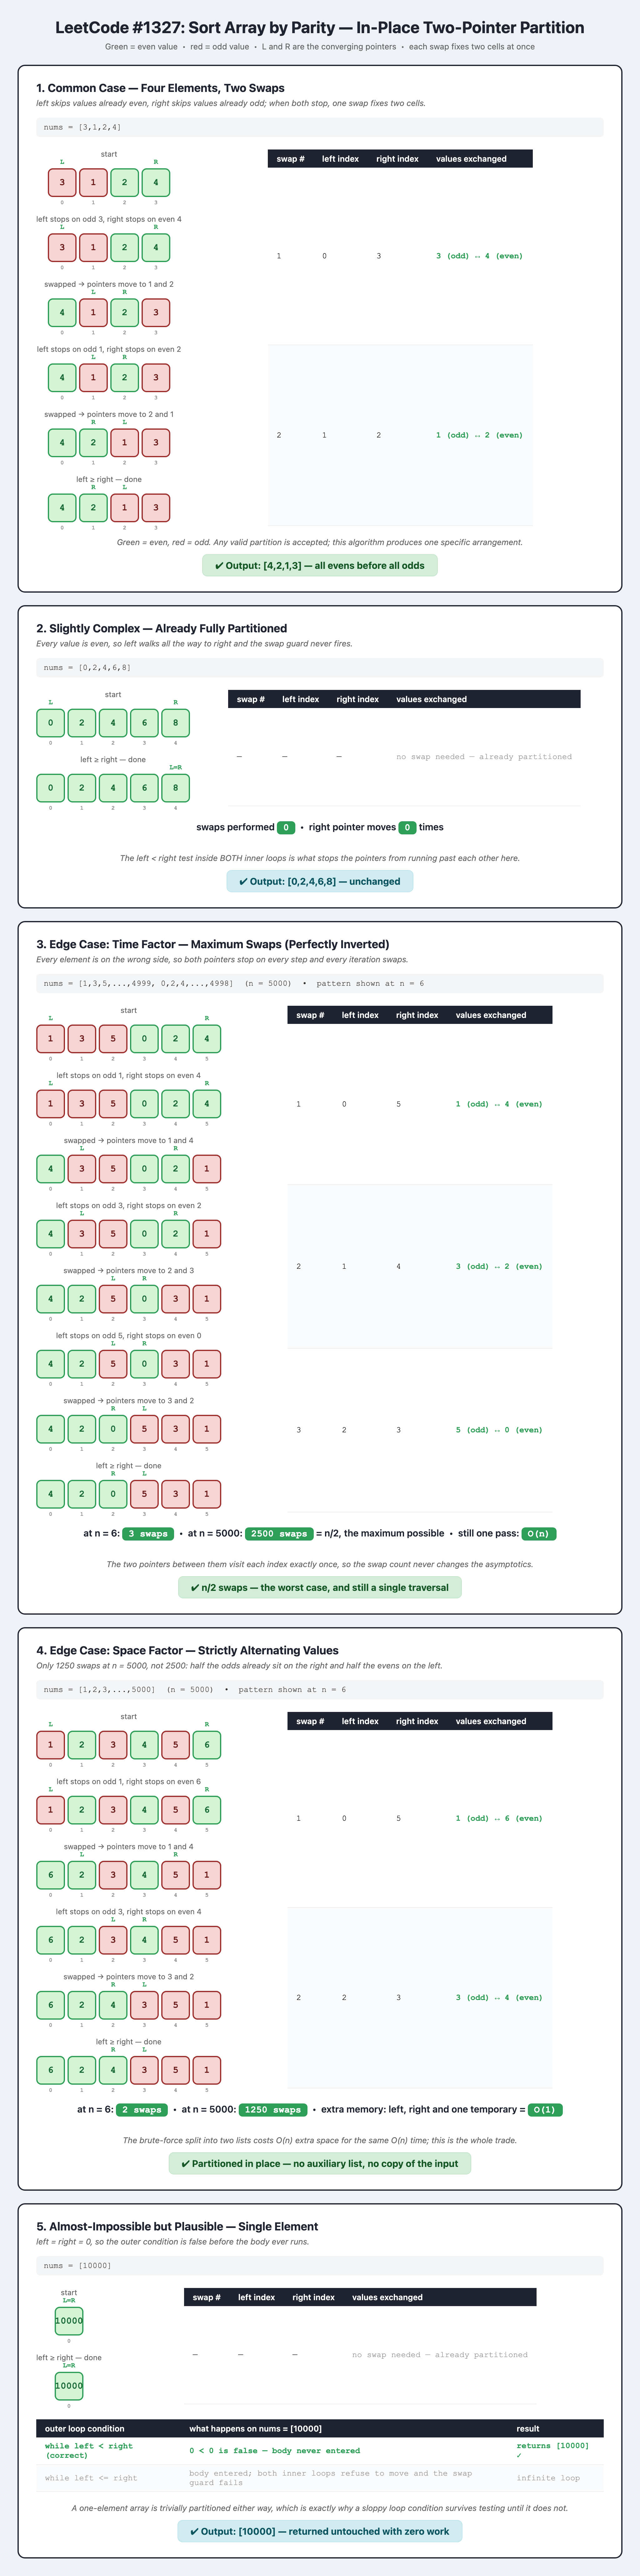